# Proyecto de mecanica  
**Integrantes:** *Maria Alejandra Diaz* 2260822 , *Daniel Alvarado Galvis* 2260803 , *Santiago Aguilar Vesga* 2260830 

**Objeto escogido:** Funda rectangular de un Ipad con masa de 120g y unas medidas de 21cm de alto y 28cm de largo 

# Metodologia 
## Grabacion 
Para registar el movimiento de un objeto de manera rotacional y traslacional debemos tener en cuenta unas consideraciones tecnicas como: 
- **Ubicacion de la camara:** Es importante que la camara se encuentre en una posicion fija durante toda la rotacion , ademas que esta se encuentre ubicada de manera horizontal y con una distancia adecuada para captar todo el movimiento
- **Marcas de referencias:** Se emplearon marcas visuales de alto contratste con el objeto, una ubicada en el centro de masa para marcar la trayectoria traslacional y otra ubicada en un punto extremo del objeto para evualuar la rotacion dada durante el movimiento
- **Adiccionalmente**: nos toco grabar de forma espejo por que al grabarlo todo el movimiento nos quedaba al eje $X$ negativo y se nos complicaria mas adelante asi que editamos el video para que se invirtiera y nos queda el movimiento hacia el eje $X$ positivo

## Importación y Calibración en Tracker 
El archivo de video generado se procesó mediante el software de análisis de video *Tracker* ejecutando los siguientes pasos de configuración inicial
- **Corte en el intervalo:** Se tomaron los fotogramas iniciales y finales de nuestro video, como punto de inicio tomamos cuando el objeto va a empezar a moverse y como punto de llegada cuando el objeto impacta con el suelo 
- **Escala:** Se uso la *Vara de calibracion* alineando con un objeto de longitud conocida, en nuestro caso una baldosa que sale en el video con medida de 257cm 
- **Sistema de referencia:** Se ubico el eje de coordenadas cartesianas $(X,Y)$ situado en la posicion inical de nuestro centro de masa nos aseguramos que el eje $Y$ positivo estuviera hacia arriba 

## Tracking 
Para capturar tanto la cinemática de traslación como la de rotación, se crearon dos *Puntos de masa* independientes 
- **Rastreo del centro:** Se rastreó fotograma a fotograma la posición $(x_A,y_A)$ de la marca ubicada en el centro del objeto rectangular Esto permitió obtener las ecuaciones de posición en función del tiempo: $x(t)$ y $y(t)$
- **Rastreo del extremo:** Se rastreó la posición $(x_B, y_B)$ del extremo superior para determinar la orientacion angular del objeto $\theta(t)$ mediante la relación trigonométrica:
$\theta(t)=\arctan2 (y_B - y_A, x_B - x_A)$
- **Metodo de rastreo:** Se empleo el rastreo manual para evitar errores por el sistema ya que el video no esta en la mejor calidad podriamos tener errores no deseados

## Exportacion de datos
Una vez completados los pasos anteriores nuestro siguiente paso era recoletar los datos obtenidos por el programa, los datos fueron exportados en una tabla estructurada con sus respectivas variables y valores. Fue exportada en formato .csv
- **Tiempo** $t$ en segundos 
- **Centro del objeto** $(x_A, y_A)$ en metros (objeto traslacional)
- **Extremo del objeto** $(x_B, y_B)$ en metros (objeto rotacional)


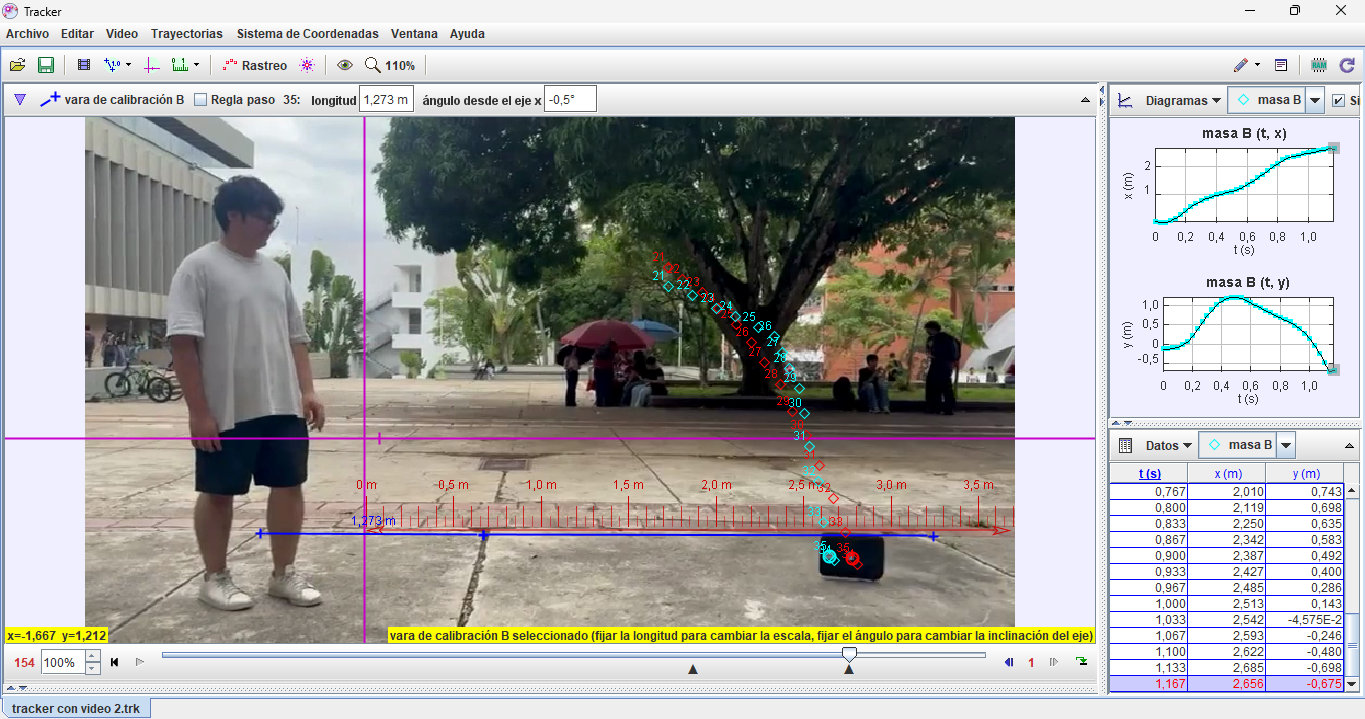

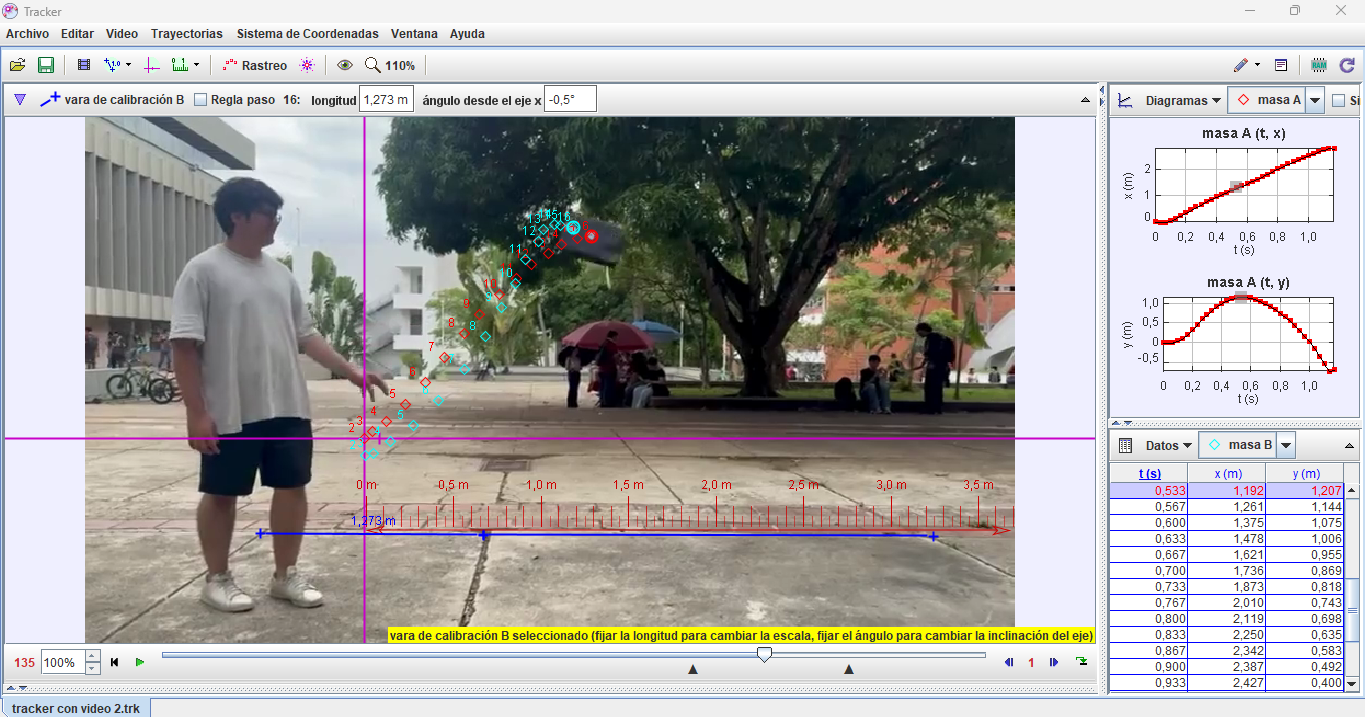

In [22]:
from IPython.display import Image, display

display(Image(filename="imagenes/captura1.png"))
display(Image(filename="imagenes/captura2.png"))

# Datos 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import animation
from matplotlib.patches import Rectangle, FancyArrowPatch
from IPython.display import HTML, Image, display

datos = pd.read_csv("datos_movimiento_tracker.csv")
datos["theta_rad"] = np.unwrap(np.arctan2(datos["yB_m"] - datos["yA_m"], datos["xB_m"] - datos["xA_m"]))

I_INI, I_FIN = 0, 35
VUELO_INI, VUELO_FIN = 6, 33

display(datos)

# --- Datos del objeto (funda de iPad)
M   = 0.120            # kg  — masa de la funda (120 g)
A_L = 0.28             # m   — largo de la cara visible (28 cm)
B_L = 0.21             # m   — alto de la cara visible (21 cm)
C_L = 0.02             # m   — espesor (no entra en I para giro en el plano)  

# --- Calibración (del .trk) y sus incertidumbres estimadas
L_CAL     = 2.57       # m   — longitud asignada a la vara de calibración
L_CAL_PX  = 410.1      # px  — longitud de la vara en el video
SIGMA_LCAL = 0.01      # m   — incertidumbre de la longitud de referencia 
SIGMA_PX   = 2.0       # px  — incertidumbre al marcar cada punto (cuadro a cuadro)

G_ACEPTADA = 9.81      # m/s² — valor aceptado de referencia 


,t_s,xA_m,yA_m,xB_m,yB_m,theta_rad
0,0.000,0.008578,0.00000,0.031450,-0.11400,-1.372794
1,0.033,-0.002859,0.00000,0.002859,-0.11400,-1.520680
2,0.067,-0.002859,0.00000,0.002859,-0.09721,-1.512043
3,0.100,0.042890,0.04003,0.048610,-0.08578,-1.525362
4,0.133,0.123000,0.09721,0.146000,-0.01716,-1.372342
5,0.167,0.232000,0.19400,0.277000,0.07434,-1.211092
6,0.200,0.346000,0.32000,0.420000,0.21700,-0.947797
7,0.233,0.455000,0.46300,0.569000,0.39500,-0.537836
8,0.267,0.569000,0.60000,0.689000,0.58300,-0.140730
9,0.300,0.655000,0.70900,0.781000,0.74900,0.307397


# Analisis del punto 2.1 al 2.5
## 2.1


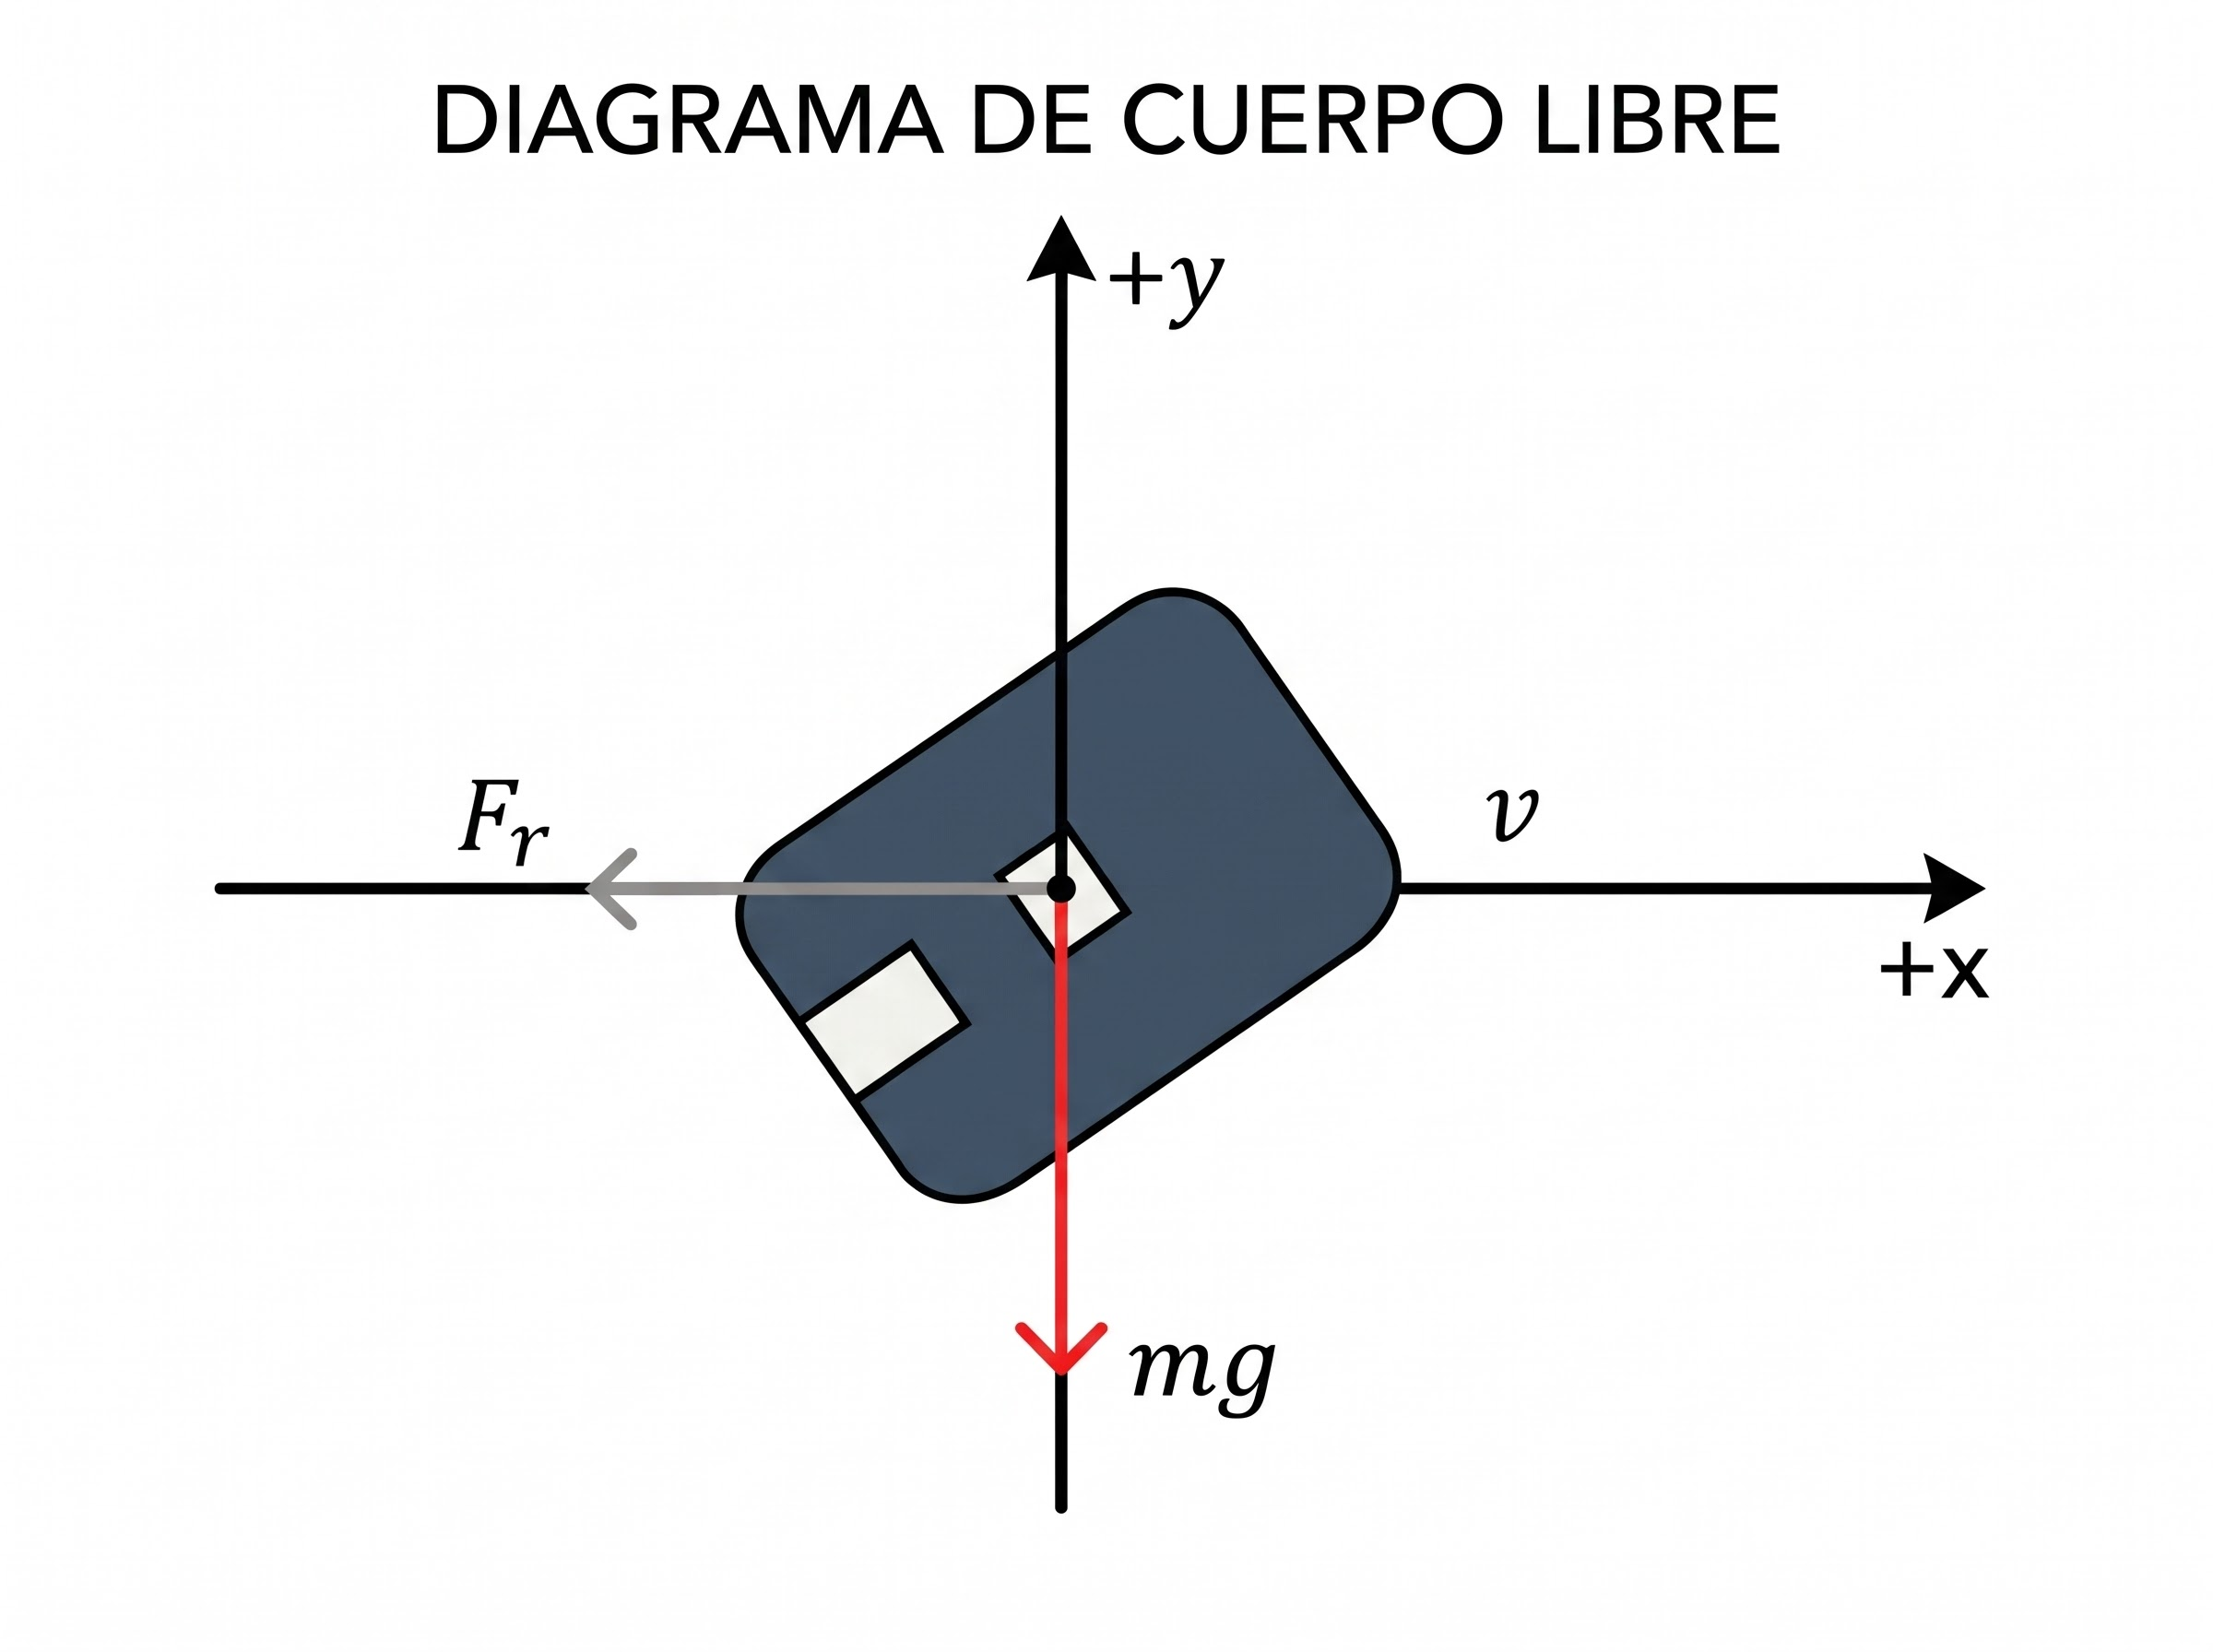

In [2]:
from IPython.display import Image, display

display(Image(filename="imagenes/dcl.jpeg"))

Durante el vuelo actúan dos fuerzas sobre la funda: el **peso** $m\vec g$, aplicado en el centro de masa y dirigido hacia abajo, y la **resistencia del aire** $\vec F_r$, opuesta a la velocidad. El diagrama muestra un instante cercano al punto más alto, donde la velocidad es horizontal y por eso $\vec F_r$ apunta hacia $-x$.

$$\sum \vec F = m\vec g + \vec F_r \neq \vec 0$$

- **No hay equilibrio:** ninguna fuerza cancela el peso ($mg \approx 1{,}18$ N), así que el centro de masa acelera. La primera condición de equilibrio no se cumple.
- **Torque respecto al CM:** el peso actúa en el CM, por lo que su brazo de palanca es cero y $\vec\tau_{peso} = \vec 0$. La resistencia del aire solo produce torque si su resultante no pasa por el CM; ese torque puede cambiar $\omega$ poco a poco. El giro no lo origina el aire: la funda ya sale girando de la mano. Si se desprecia el aire, $\vec L_{cm} = I_{cm}\vec\omega$ se conserva y **$\omega$ es constante**.

## 2.2
- **centro de masa**

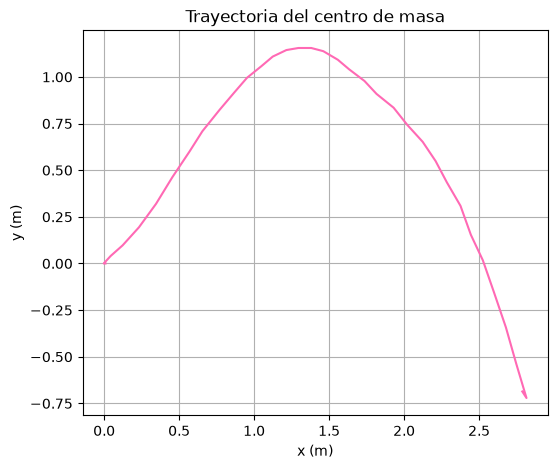

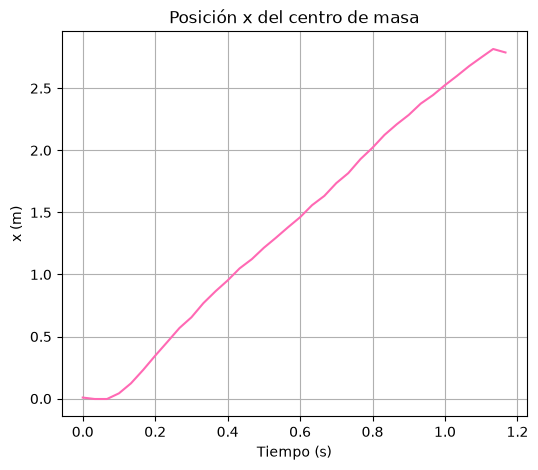

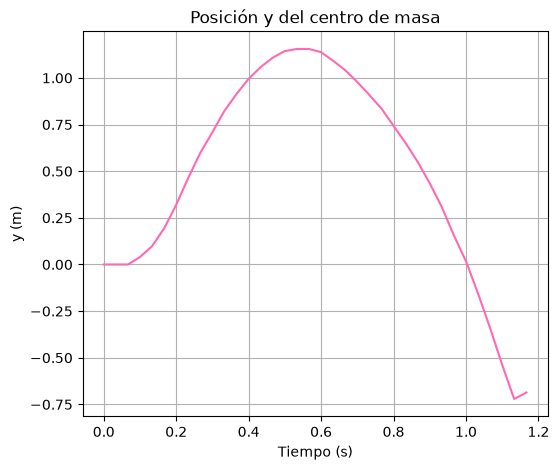

In [3]:
# 1. Trayectoria y(x) del centro de masa
plt.figure(figsize=(6, 5))
plt.plot(datos["xA_m"], datos["yA_m"], color="hotpink")
plt.title("Trayectoria del centro de masa")
plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.grid()
plt.show()


# 2. Posición x(t) del centro de masa
plt.figure(figsize=(6, 5))
plt.plot(datos["t_s"], datos["xA_m"], color="hotpink")
plt.title("Posición x del centro de masa")
plt.xlabel("Tiempo (s)")
plt.ylabel("x (m)")
plt.grid()
plt.show()


# 3. Posición y(t) del centro de masa
plt.figure(figsize=(6, 5))
plt.plot(datos["t_s"], datos["yA_m"], color="hotpink")
plt.title("Posición y del centro de masa")
plt.xlabel("Tiempo (s)")
plt.ylabel("y (m)")
plt.grid()
plt.show()




- **Extremo**


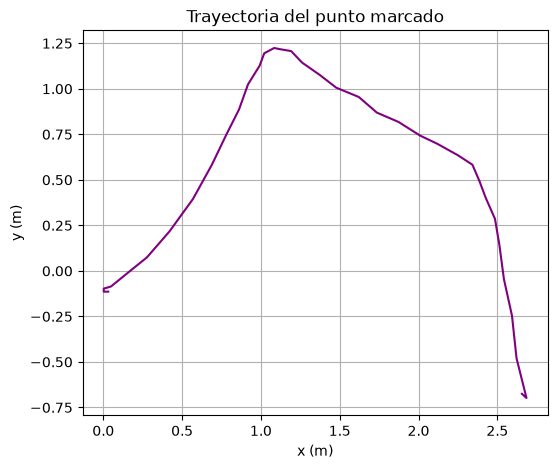

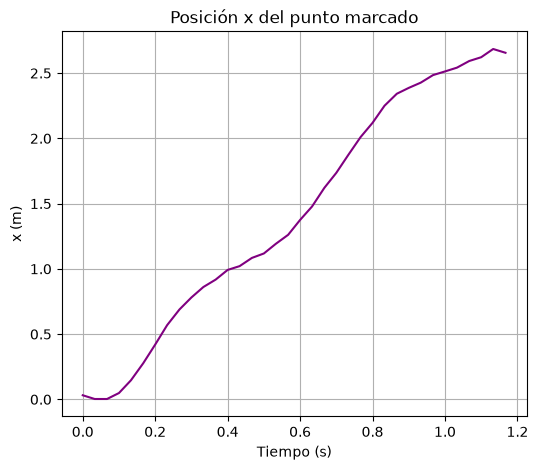

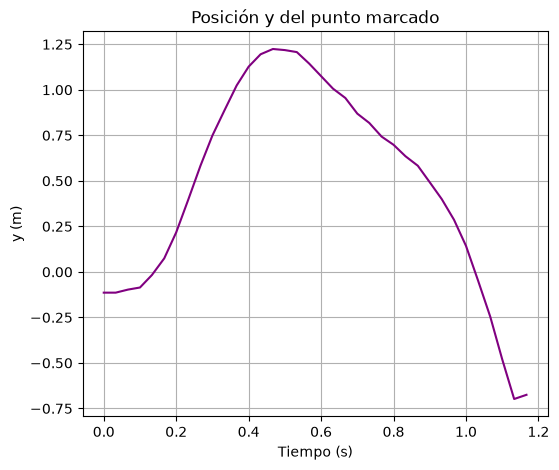

In [4]:
# 4. Trayectoria y(x) del punto marcado
plt.figure(figsize=(6, 5))
plt.plot(datos["xB_m"], datos["yB_m"], color="purple")
plt.title("Trayectoria del punto marcado")
plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.grid()
plt.show()


# 5. Posición x(t) del punto marcado
plt.figure(figsize=(6, 5))
plt.plot(datos["t_s"], datos["xB_m"], color="purple")
plt.title("Posición x del punto marcado")
plt.xlabel("Tiempo (s)")
plt.ylabel("x (m)")
plt.grid()
plt.show()


# 6. Posición y(t) del punto marcado
plt.figure(figsize=(6, 5))
plt.plot(datos["t_s"], datos["yB_m"], color="purple")
plt.title("Posición y del punto marcado")
plt.xlabel("Tiempo (s)")
plt.ylabel("y (m)")
plt.grid()
plt.show()

- **ajuste por minimos cuadados**

centro de masa 

$x(t)= v_x t + x_0$

$y(t)= At^2 +Bt+C $


Punto marcado(extremo)

$x(t)= v_x t + x_0$

$y(t)= At^2 +Bt+C $

La pendiente de \(x(t)\) representa la velocidad horizontal.


El doble del coeficiente \(A\) representa la aceleración vertical.


El coeficiente \(B\) representa la velocidad vertical inicial.


El coeficiente \(C\) representa la posición vertical inicial.

In [5]:
# Ajustes del centro de masa
coef_x_centro, cov_x_centro = np.polyfit(
    datos["t_s"], datos["xA_m"], 1, cov=True
)

coef_y_centro, cov_y_centro = np.polyfit(
    datos["t_s"], datos["yA_m"], 2, cov=True
)

# Ajustes del punto marcado
coef_x_punto, cov_x_punto = np.polyfit(
    datos["t_s"], datos["xB_m"], 1, cov=True
)

coef_y_punto, cov_y_punto = np.polyfit(
    datos["t_s"], datos["yB_m"], 2, cov=True
)


# Incertidumbres de los coeficientes
inc_x_centro = np.sqrt(np.diag(cov_x_centro))
inc_y_centro = np.sqrt(np.diag(cov_y_centro))

inc_x_punto = np.sqrt(np.diag(cov_x_punto))
inc_y_punto = np.sqrt(np.diag(cov_y_punto))


# Mostrar resultados
print("CENTRO DE MASA")

print("x(t) = v*t + x0")
print(f"v = {coef_x_centro[0]:.6f} ± {inc_x_centro[0]:.6f} m/s")
print(f"x0 = {coef_x_centro[1]:.6f} ± {inc_x_centro[1]:.6f} m")

print("\ny(t) = A*t² + B*t + C")
print(f"A = {coef_y_centro[0]:.6f} ± {inc_y_centro[0]:.6f} m/s²")
print(f"B = {coef_y_centro[1]:.6f} ± {inc_y_centro[1]:.6f} m/s")
print(f"C = {coef_y_centro[2]:.6f} ± {inc_y_centro[2]:.6f} m")


print("\nPUNTO MARCADO")

print("x(t) = v*t + x0")
print(f"v = {coef_x_punto[0]:.6f} ± {inc_x_punto[0]:.6f} m/s")
print(f"x0 = {coef_x_punto[1]:.6f} ± {inc_x_punto[1]:.6f} m")

print("\ny(t) = A*t² + B*t + C")
print(f"A = {coef_y_punto[0]:.6f} ± {inc_y_punto[0]:.6f} m/s²")
print(f"B = {coef_y_punto[1]:.6f} ± {inc_y_punto[1]:.6f} m/s")
print(f"C = {coef_y_punto[2]:.6f} ± {inc_y_punto[2]:.6f} m")

CENTRO DE MASA
x(t) = v*t + x0
v = 2.641231 ± 0.025869 m/s
x0 = -0.128864 ± 0.017549 m

y(t) = A*t² + B*t + C
A = -4.857185 ± 0.170258 m/s²
B = 5.244970 ± 0.205501 m/s
C = -0.346897 ± 0.051814 m

PUNTO MARCADO
x(t) = v*t + x0
v = 2.566008 ± 0.052052 m/s
x0 = -0.076594 ± 0.035311 m

y(t) = A*t² + B*t + C
A = -4.985662 ± 0.211127 m/s²
B = 5.517691 ± 0.254830 m/s
C = -0.447248 ± 0.064251 m


de esta manera nos quedan las ecuaciones

Centro de masa

$x(t) = (2.641231 ± 0.025869)t - (0.128864 ± 0.017549)$

$y(t)= (-4.857185 ± 0.170258)t^2 + ( 5.244970 ± 0.205501)t - (0.346897 ± 0.051814) $

Punto marcado (extremo)

$x(t) = (2.566008 ± 0.052052)t - (0.076594 ± 0.035311)$

$y(t)= (-4.985662 ± 0.211127)t^2 + ( 5.517691 ± 0.254830)t - (0.447248 ± 0.064251) $



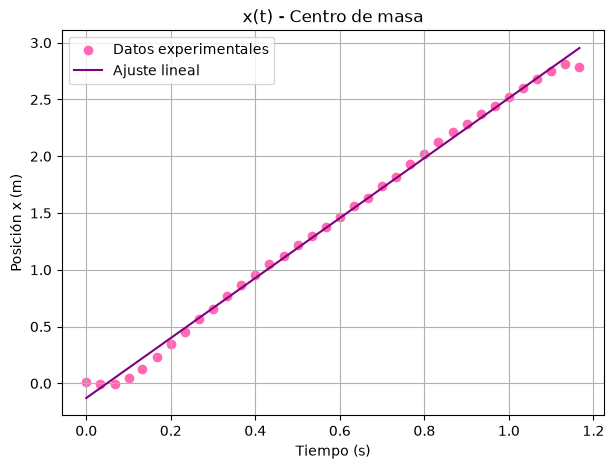

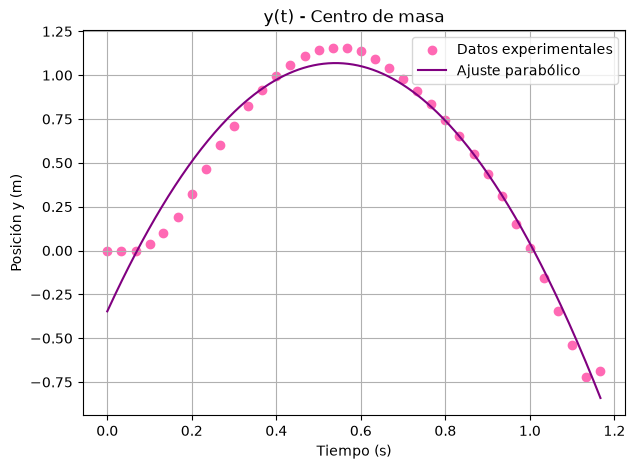

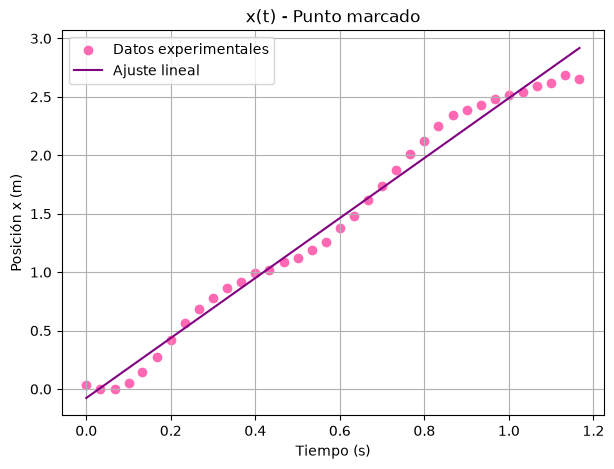

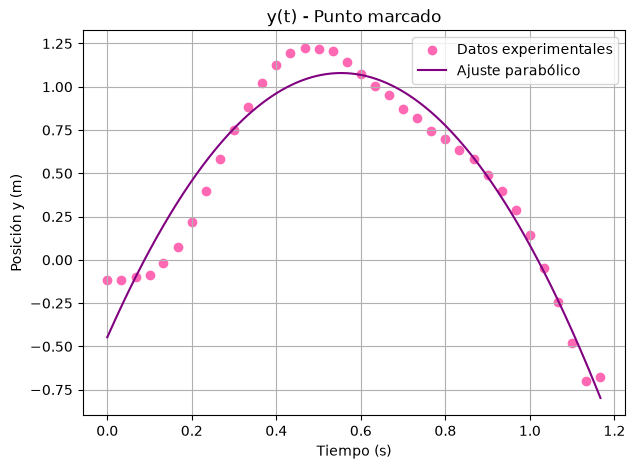

In [6]:
t = datos["t_s"]
t_ajuste = np.linspace(t.min(), t.max(), 300)

# Ajustes
x_ajuste_centro = np.poly1d(coef_x_centro)
y_ajuste_centro = np.poly1d(coef_y_centro)

x_ajuste_punto = np.poly1d(coef_x_punto)
y_ajuste_punto = np.poly1d(coef_y_punto)


# 1. x(t) - Centro de masa

plt.figure(figsize=(7,5))
plt.scatter(t, datos["xA_m"], color="hotpink", label="Datos experimentales")
plt.plot(t_ajuste, x_ajuste_centro(t_ajuste), color="purple", label="Ajuste lineal")
plt.title("x(t) - Centro de masa")
plt.xlabel("Tiempo (s)")
plt.ylabel("Posición x (m)")
plt.grid()
plt.legend()
plt.show()


# 2. y(t) - Centro de masa
plt.figure(figsize=(7,5))
plt.scatter(t, datos["yA_m"], color="hotpink", label="Datos experimentales")
plt.plot(t_ajuste, y_ajuste_centro(t_ajuste), color="purple", label="Ajuste parabólico")
plt.title("y(t) - Centro de masa")
plt.xlabel("Tiempo (s)")
plt.ylabel("Posición y (m)")
plt.grid()
plt.legend()
plt.show()


# 3. x(t) - Punto marcado
plt.figure(figsize=(7,5))
plt.scatter(t, datos["xB_m"], color="hotpink", label="Datos experimentales")
plt.plot(t_ajuste, x_ajuste_punto(t_ajuste), color="purple", label="Ajuste lineal")
plt.title("x(t) - Punto marcado")
plt.xlabel("Tiempo (s)")
plt.ylabel("Posición x (m)")
plt.grid()
plt.legend()
plt.show()


# 4. y(t) - Punto marcado
plt.figure(figsize=(7,5))
plt.scatter(t, datos["yB_m"], color="hotpink", label="Datos experimentales")
plt.plot(t_ajuste, y_ajuste_punto(t_ajuste), color="purple", label="Ajuste parabólico")
plt.title("y(t) - Punto marcado")
plt.xlabel("Tiempo (s)")
plt.ylabel("Posición y (m)")
plt.grid()
plt.legend()
plt.show()

**Significado físico de los coeficientes** ($y = y_0 + v_{0y}t - \tfrac12 g t^2$):
- $y_0$: altura del CM en $t = 0$ según la parábola. Da $-0{,}347 \pm 0{,}052$ m, aunque la posición medida en esa fila es $0$. La diferencia aparece porque en los primeros cuadros la funda sigue en la mano y no describe la parábola.
- $v_{0y}$: velocidad vertical en $t = 0$ según la parábola, $5{,}25 \pm 0{,}21$ m/s.
- $-\tfrac12 g$: el coeficiente cuadrático es la mitad de la aceleración del CM. Sale negativo porque el eje $y$ apunta hacia arriba.
- En $x(t)$: $x_0$ es la posición inicial y la pendiente es $v_{0x} = 2{,}64 \pm 0{,}03$ m/s, constante si no hay fuerza horizontal.


In [7]:
tabla = pd.DataFrame({
    "Magnitud": ["y₀ (m)", "v₀ᵧ (m/s)", "g (m/s²)"],
    "Centro de masa": [-0.346897, 5.244970, 9.714370],
    "Punto marcado": [-0.447248, 5.517691, 9.971324]
})


display(tabla.round(6))

,Magnitud,Centro de masa,Punto marcado
0,y₀ (m),-0.346897,-0.447248
1,v₀ᵧ (m/s),5.244970,5.517691
2,g (m/s²),9.714370,9.971324


- ¿Que tan cerca esta la gravedad del valor aceptado?

Teniendo en cuenta que el valor de la gravedad es 9.81

calculamos el valor porcentual 

$Error = \frac{|g_{exp} - g_{aceptada}|}{g_{aceptado}} * 100$

**centro de masa**

$Error = \frac{|9.714370 - 9.81|}{9.81} * 100$

$Error = 0.975 \% $

**extremo marcado**

$Error = \frac{|9.971324 - 9.81|}{9.81} * 100$

$Error = 1.644\% $


los valores obtenidos experimentalmente fueron $9.714370 m/s^2$  para el centro de masa y $9.971324 m/s^2$ para el extremo. estos presentan valores errores porcentuales de 0.975% y 1.644% respectivamente, respecto al valor aceptado de $9.81m/s^2$. Por tanto, ambos resultados presentan una buena aproximacion al valor teorico 


In [8]:
# Excluir los tres primeros datos en reposo
movimiento = datos.iloc[2:].copy()

# Primeros cinco puntos del movimiento
primeros = movimiento.iloc[:5]

# Ajustes lineales
vx0 = np.polyfit(
    primeros["t_s"],
    primeros["xA_m"], 1
)[0]

vy0 = np.polyfit(
    primeros["t_s"],
    primeros["yA_m"], 1
)[0]

# Rapidez y ángulo
v0 = np.sqrt(vx0**2 + vy0**2)
angulo = np.degrees(np.arctan2(vy0, vx0))


y_inicial = movimiento["yA_m"].iloc[0]
y_max = movimiento["yA_m"].max()
altura_max = y_max - y_inicial

#alcance horizontal
alcance = movimiento["xA_m"].iloc[-1] - movimiento["xA_m"].iloc[0]


resultados = pd.DataFrame({
    "Magnitud": [
        "Velocidad inicial X (m/s)",
        "Velocidad inicial Y (m/s)",
        "Rapidez inicial (m/s)",
        "Ángulo de lanzamiento (°)",
        "Altura máxima (m)",
        "Alcance horizontal (m)"
    ],
    "Resultado": [
        vx0,
        vy0,
        v0,
        angulo,
        altura_max,
        alcance
    ]
})

display(resultados.round(6))

,Magnitud,Resultado
0,Velocidad inicial X (m/s),2.664476
1,Velocidad inicial Y (m/s),2.385611
2,Rapidez inicial (m/s),3.576391
3,Ángulo de lanzamiento (°),41.839338
4,Altura máxima (m),1.155000
5,Alcance horizontal (m),2.790859


eso usando los datos del tracker, para usar la ecuacion usariamos la aproximacion por cuadrados 

## 2.3


Transformación galileana al sistema del CM: $\vec r_{B/A} = \vec r_B - \vec r_A$. El ángulo del punto marcado es

$$\theta(t) = \operatorname{atan2}\!\left(y_B - y_A,\; x_B - x_A\right)$$

y se desenrolla con `np.unwrap` para eliminar los saltos de $\pm 2\pi$. Para rotación uniforme, $\theta(t) = \theta_0 + \omega t$.

In [9]:
tramo = datos.iloc[I_INI:I_FIN + 1].reset_index(drop=True)
t = tramo["t_s"].to_numpy()
t = t - t[0]                                       # t = 0 en la primera fila analizada
xA, yA = tramo["xA_m"].to_numpy(), tramo["yA_m"].to_numpy()   # centro de masa
xB, yB = tramo["xB_m"].to_numpy(), tramo["yB_m"].to_numpy()   # punto marcado
N = len(t)
en_vuelo = (np.arange(N) + I_INI >= VUELO_INI) & (np.arange(N) + I_INI <= VUELO_FIN)



def ajuste(t, y, grado):
    c, cov = np.polyfit(t, y, grado, cov=True)
    return c, np.sqrt(np.diag(cov)), cov

cx, sx, covx = ajuste(t, xA, 1)          
cy, sy, covy = ajuste(t, yA, 2)

v0x, s_v0x = cx[0], sx[0]
x0,  s_x0  = cx[1], sx[1]
g_fit, s_g_fit = -2 * cy[0], 2 * sy[0]
v0y, s_v0y = cy[1], sy[1]
y0,  s_y0  = cy[2], sy[2]
v0  = np.hypot(v0x, v0y)
ang0 = np.degrees(np.arctan2(v0y, v0x))

In [10]:
dx = xB - xA
dy = yB - yA
r_i = np.hypot(dx, dy)
theta_crudo = np.arctan2(dy, dx)
theta = np.unwrap(theta_crudo)                         # sin saltos de 2π

ct, st, covt = ajuste(t, theta, 1)
omega, s_omega = ct[0], st[0]
theta0, s_theta0 = ct[1], st[1]
r_med, s_r = r_i.mean(), r_i.std(ddof=1)

# Prueba de constancia: ¿la aceleración angular de un ajuste cuadrático es compatible con 0?
cq, sq, _ = ajuste(t, theta, 2)
alfa, s_alfa = 2 * cq[0], 2 * sq[0]

tabla_angular = pd.DataFrame({
    "Magnitud": [
        "Posición angular inicial (rad)",
        "Velocidad angular (rad/s)",
        "Velocidad de giro (vueltas/s)",
        "Sentido de rotación",
        "Vueltas durante el vuelo"
    ],
    "Resultado": [
        f"{theta0:.3f} ± {s_theta0:.3f}",
        f"{omega:.2f} ± {s_omega:.2f}",
        f"{omega/(2*np.pi):.2f}",
        "Antihorario" if omega > 0 else "Horario",
        f"{(theta[-1]-theta[0])/(2*np.pi):.2f}"
    ]
})

tabla_constancia = pd.DataFrame({
    "Magnitud": [
        "Aceleración angular (rad/s²)",
        "Compatibilidad con cero (criterio 2σ)",
        "Radio promedio (m)"
    ],
    "Resultado": [
        f"{alfa:.1f} ± {s_alfa:.1f}",
        "Compatible" if abs(alfa) < 2*s_alfa else "No compatible",
        f"{r_med:.4f} ± {s_r:.4f}"
    ]
})

display(tabla_angular)
display(tabla_constancia)

,Magnitud,Resultado
0,Posición angular inicial (rad),-2.580 ± 0.106
1,Velocidad angular (rad/s),10.41 ± 0.16
2,Velocidad de giro (vueltas/s),1.66
3,Sentido de rotación,Antihorario
4,Vueltas durante el vuelo,1.71


,Magnitud,Resultado
0,Aceleración angular (rad/s²),2.5 ± 0.9
1,Compatibilidad con cero (criterio 2σ),No compatible
2,Radio promedio (m),0.1212 ± 0.0122


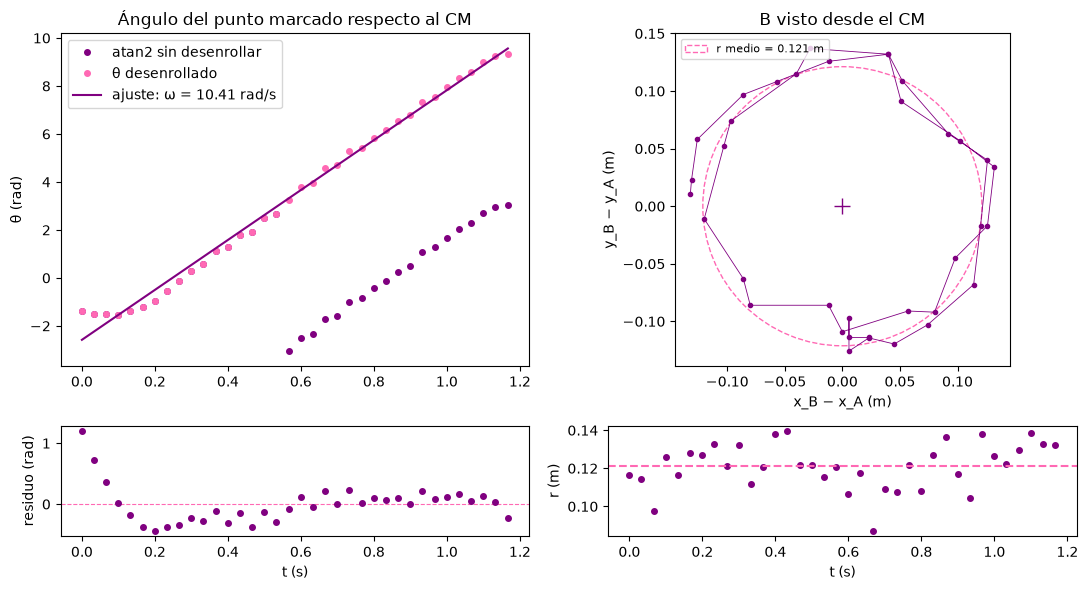

In [11]:
tt = np.linspace(0, t[-1], 300)

fig, axs = plt.subplots(2, 2, figsize=(11, 6), gridspec_kw={"height_ratios": [3, 1]})

# --- Columna 1: Ángulo y su Residuo ---
# Ángulo
axs[0, 0].plot(t, theta_crudo, "o", ms=4, color="Purple", label="atan2 sin desenrollar")
axs[0, 0].plot(t, theta, "o", ms=4, color="Hotpink", label="θ desenrollado")
axs[0, 0].plot(tt, np.polyval(ct, tt), "-", color="Purple", label=f"ajuste: ω = {omega:.2f} rad/s")
axs[0, 0].set(title="Ángulo del punto marcado respecto al CM", ylabel="θ (rad)")
axs[0, 0].legend()

# Residuo Ángulo
axs[1, 0].axhline(0, color="Hotpink", lw=0.8, ls="--")
axs[1, 0].plot(t, theta - np.polyval(ct, t), "o", ms=4, color="Purple")
axs[1, 0].set(xlabel="t (s)", ylabel="residuo (rad)")

# --- Columna 2: Trayectoria y Residuo del Radio ---
# Trayectoria
axs[0, 1].plot(dx, dy, "o-", ms=3, lw=0.6, color="Purple")
axs[0, 1].add_patch(plt.Circle((0, 0), r_med, fill=False, ls="--", color="Hotpink", label=f"r medio = {r_med:.3f} m"))
axs[0, 1].plot(0, 0, "+", color="Purple", ms=12)
axs[0, 1].set(title="B visto desde el CM", xlabel="x_B − x_A (m)", ylabel="y_B − y_A (m)")
axs[0, 1].set_aspect("equal")
axs[0, 1].legend(fontsize=8)

# Residuo / Variación del Radio
axs[1, 1].plot(t, r_i, "o", ms=4, color="Purple")
axs[1, 1].axhline(r_med, color="Hotpink", ls="--")
axs[1, 1].set(xlabel="t (s)", ylabel="r (m)")

plt.tight_layout()
plt.show()
plt.show()

**Relación $v_{rel} = \omega r$.** Se deriva numéricamente la posición relativa (diferencias centradas, `np.gradient`) y se compara su rapidez con $\omega r$. Además se verifica la composición de velocidades de un cuerpo rígido:

$$\vec v_B = \vec v_{cm} + \vec\omega\times\vec r_{B/A}$$

,Magnitud,Resultado
0,Velocidad relativa medida (m/s),1.17 ± 0.36
1,Velocidad relativa teórica ω·r (m/s),1.26 ± 0.13


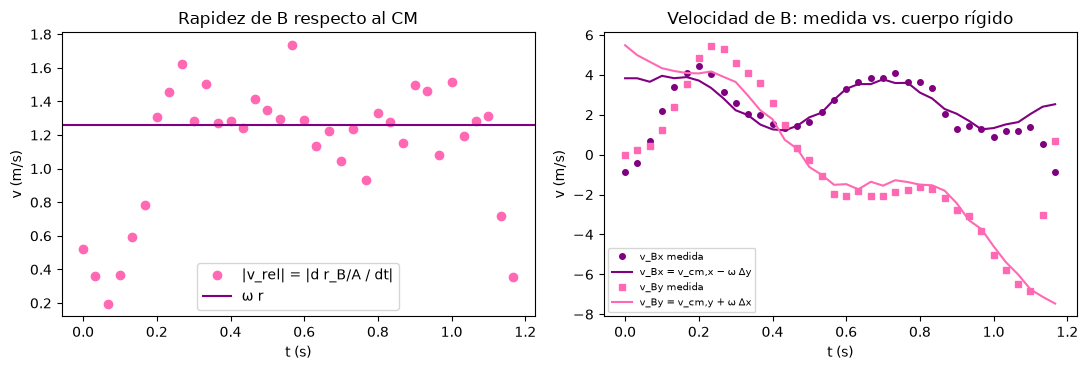

In [12]:


vrel_x, vrel_y = np.gradient(dx, t), np.gradient(dy, t)
v_rel = np.hypot(vrel_x, vrel_y)
v_rel_teo = abs(omega) * r_med

# Velocidad de B medida vs. predicha por cuerpo rígido (ω k̂ × r = ω(−dy, dx))
vBx_med, vBy_med = np.gradient(xB, t), np.gradient(yB, t)
vcm_x = np.full_like(t, v0x)                       # del ajuste de x(t)
vcm_y = v0y - g_fit * t                            # del ajuste de y(t)
vBx_rig, vBy_rig = vcm_x - omega * dy, vcm_y + omega * dx

tablanovcircular = pd.DataFrame({
    "Magnitud": [
        "Velocidad relativa medida (m/s)",
        "Velocidad relativa teórica ω·r (m/s)"
    ],
    "Resultado": [
        f"{v_rel[1:-1].mean():.2f} ± {v_rel[1:-1].std(ddof=1):.2f}",
        f"{v_rel_teo:.2f} ± {v_rel_teo*np.hypot(s_omega/omega, s_r/r_med):.2f}"
    ]
})

display(tablanovcircular)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].plot(t, v_rel, "o", color="hotpink", label="|v_rel| = |d r_B/A / dt|")
axs[0].axhline(v_rel_teo, color="purple", label="ω r")
axs[0].set(title="Rapidez de B respecto al CM", xlabel="t (s)", ylabel="v (m/s)"); axs[0].legend()
axs[1].plot(t, vBx_med, "o", ms=4, color="purple", label="v_Bx medida")
axs[1].plot(t, vBx_rig, "-", color="purple", label="v_Bx = v_cm,x − ω Δy")
axs[1].plot(t, vBy_med, "s", ms=4, color="hotpink", label="v_By medida")
axs[1].plot(t, vBy_rig, "-", color="hotpink", label="v_By = v_cm,y + ω Δx")
axs[1].set(title="Velocidad de B: medida vs. cuerpo rígido", xlabel="t (s)", ylabel="v (m/s)")
axs[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

La pendiente da $\omega = 10{,}41 \pm 0{,}16$ rad/s. Los residuos muestran que la rotación no es uniforme en todo el intervalo: en los primeros cuadros, cuando la funda sigue en la mano, $\theta$ casi no cambia, y el ajuste cuadrático da $\alpha = 2{,}5 \pm 0{,}9$ rad/s², distinto de 0. En vuelo libre (ver 2.5), $\omega = 11{,}04 \pm 0{,}08$ rad/s y $\alpha = -1{,}6 \pm 0{,}6$ rad/s², una variación pequeña frente a $\omega$. La relación $v_{rel} = \omega r$ se cumple dentro de la incertidumbre: $1{,}17 \pm 0{,}36$ m/s frente a $1{,}26 \pm 0{,}13$ m/s.

## 2.4
$$E_{tras} = \tfrac12 m v_{cm}^2, \qquad E_{rot} = \tfrac12 I_{cm}\,\omega^2, \qquad E_p = m g\, y_{cm}$$

**Momento de inercia.** Para una placa/caja rectangular de lados $a$ y $b$ que gira alrededor de un eje perpendicular a esa cara y que pasa por su centro:

$$I_{cm} = \tfrac{1}{12} m\,(a^2 + b^2)$$

(Serway & Jewett, *Física para ciencias e ingeniería*, Vol. 1, tabla 10.2). El espesor $c$ no aparece porque el eje es paralelo a él.

Las velocidades del CM se obtienen por diferencias centradas de los datos medidos, no del ajuste, para que la prueba de conservación sea independiente del modelo. $E_p$ se calcula con dos valores de $g$: la aceptada y la ajustada.

,Magnitud,Resultado
0,Momento de inercia (kg·m²),0.001225
1,Longitud a (m),0.280000
2,Longitud b (m),0.210000
3,Masa (kg),0.120000


,Magnitud,Resultado
0,Relación E_rot / E_tras en vuelo libre,0.069
1,Energía total: media (todas las filas) (J),1.540
2,Variación máxima (todas las filas) (J),3.048
3,Variación porcentual (todas las filas) (%),197.863
4,Desviación estándar (todas las filas) (J),0.800
5,Energía total: media (vuelo libre) (J),1.916
6,Variación máxima (vuelo libre) (J),0.692
7,Variación porcentual (vuelo libre) (%),36.106
8,Desviación estándar (vuelo libre) (J),0.163
9,Tendencia de energía en vuelo libre (J/s),-0.442


,Magnitud,Resultado
0,Incertidumbre de la tendencia (J/s),0.078


C:\Users\LADY DIAZ\AppData\Local\Temp\ipykernel_17992\3025744496.py:65: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k-" (-> color='k'). The keyword argument will take precedence.
  ax.plot(t, Et, "k-", lw=2.2,color="lightblue", label="E mecánica total" )


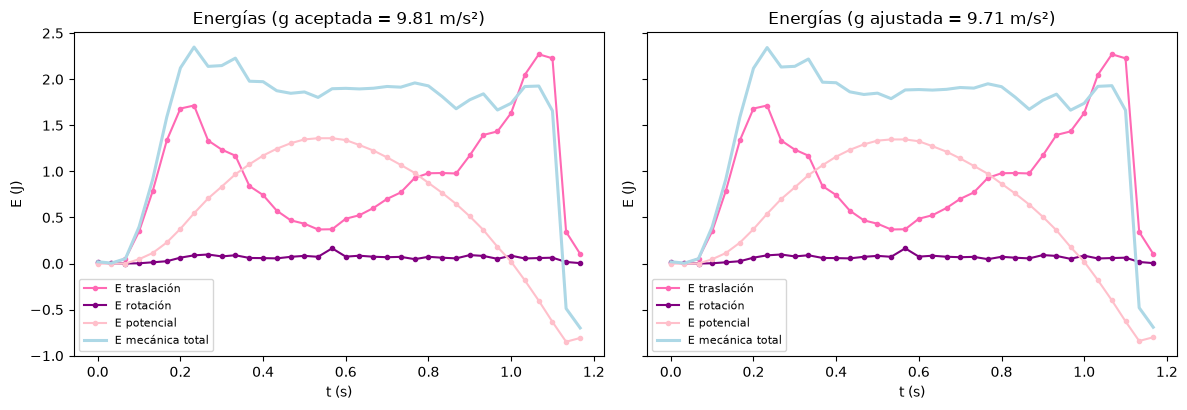

In [13]:
I_cm = M * (A_L**2 + B_L**2) / 12

vx_cm, vy_cm = np.gradient(xA, t), np.gradient(yA, t)
v2_cm = vx_cm**2 + vy_cm**2
omega_i = np.gradient(theta, t)                       # ω instantánea

E_tras = 0.5 * M * v2_cm
E_rot  = 0.5 * I_cm * omega_i**2
E_p_acep = M * G_ACEPTADA * yA
E_p_fit  = M * g_fit * yA
E_tot_acep = E_tras + E_rot + E_p_acep
E_tot_fit  = E_tras + E_rot + E_p_fit

cE, sE, _ = ajuste(t[en_vuelo], E_tot_acep[en_vuelo], 1)

# Tabla 1: Parámetros del momento de inercia
tabla_inercia = pd.DataFrame({
    "Magnitud": ["Momento de inercia (kg·m²)", "Longitud a (m)", "Longitud b (m)", "Masa (kg)"],
    "Resultado": [I_cm, A_L, B_L, M]
})

# Tabla 2: Energía y conservación
tabla_energia = pd.DataFrame({
    "Magnitud": [
        "Relación E_rot / E_tras en vuelo libre",
        "Energía total: media (todas las filas) (J)",
        "Variación máxima (todas las filas) (J)",
        "Variación porcentual (todas las filas) (%)",
        "Desviación estándar (todas las filas) (J)",
        "Energía total: media (vuelo libre) (J)",
        "Variación máxima (vuelo libre) (J)",
        "Variación porcentual (vuelo libre) (%)",
        "Desviación estándar (vuelo libre) (J)",
        "Tendencia de energía en vuelo libre (J/s)"
    ],
    "Resultado": [
        E_rot[en_vuelo].mean() / E_tras[en_vuelo].mean(),
        E_tot_acep.mean(),
        E_tot_acep.max() - E_tot_acep.min(),
        100 * (E_tot_acep.max() - E_tot_acep.min()) / E_tot_acep.mean(),
        E_tot_acep.std(ddof=1),
        E_tot_acep[en_vuelo].mean(),
        E_tot_acep[en_vuelo].max() - E_tot_acep[en_vuelo].min(),
        100 * (E_tot_acep[en_vuelo].max() - E_tot_acep[en_vuelo].min()) / E_tot_acep[en_vuelo].mean(),
        E_tot_acep[en_vuelo].std(ddof=1),
        cE[0]
    ]
})

# Tabla 3: Incertidumbre de la tendencia
tabla_tendencia = pd.DataFrame({
    "Magnitud": ["Incertidumbre de la tendencia (J/s)"],
    "Resultado": [sE[0]]
})

display(tabla_inercia)
display(tabla_energia.round(3))
display(tabla_tendencia.round(3))
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, Ep, Et, nom in [(axs[0], E_p_acep, E_tot_acep, f"g aceptada = {G_ACEPTADA}"),
                        (axs[1], E_p_fit, E_tot_fit, f"g ajustada = {g_fit:.2f}")]:
    ax.plot(t, E_tras, "o-", ms=3,color="hotpink", label="E traslación")
    ax.plot(t, E_rot, "o-", ms=3,color="purple", label="E rotación")
    ax.plot(t, Ep, "o-", ms=3,color="pink", label="E potencial")
    ax.plot(t, Et, "k-", lw=2.2,color="lightblue", label="E mecánica total" )
    ax.set(title=f"Energías ({nom} m/s²)", xlabel="t (s)", ylabel="E (J)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

- **Energía mecánica:** No, la energía mecánica no se conserva a lo largo del intervalo analizado, registrando una variación total de 3,05 J que equivale al 198 % respecto a su valor medio. Esta fluctuación se explica principalmente porque el modelo de vuelo libre no aplica en todo el registro: al inicio, la mano realiza trabajo externo sobre la funda para impulsarla entregándole energía, mientras que los datos del final capturan el instante posterior al impacto, donde la energía se disipa irreversiblemente en forma de sonido, calor y deformación. Asimismo, durante el trayecto actúa la resistencia del aire como una fuerza no conservativa que disipa energía de manera continua, a lo que se suman los errores experimentales inherentes a la medición, tales como el ruido en la detección de posiciones y la propagación de incertidumbres al derivar la velocidad, los cuales introducen variaciones numéricas en el cálculo de la energía cinética y potencial.

,Magnitud,Resultado
0,Momento lineal medio (kg·m/s),0.2763 ± 0.0204
1,Dispersión del momento lineal (kg·m/s),0.1227
2,Pendiente dp_x/dt (N),-0.0166 ± 0.0598
3,Compatibilidad de la pendiente con 0 (2σ),Compatible
4,Pendiente solo vuelo libre (N),-0.1076 ± 0.0194
5,Compatibilidad en vuelo libre con 0 (2σ),No compatible


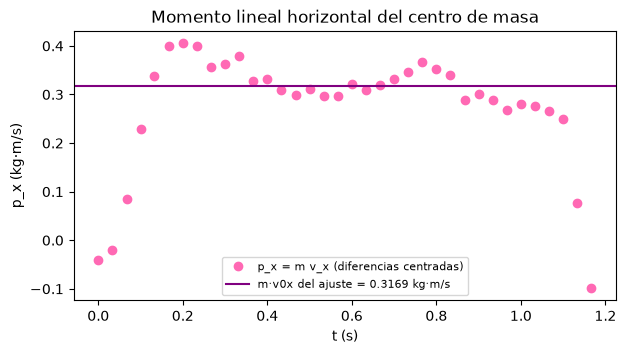

In [14]:
# Momento lineal horizontal del CM
p_x = M * vx_cm
cp, sp, _ = ajuste(t, p_x, 1)
cpv, spv, _ = ajuste(t[en_vuelo], p_x[en_vuelo], 1)

tabla_momento = pd.DataFrame({
    "Magnitud": [
        "Momento lineal medio (kg·m/s)",
        "Dispersión del momento lineal (kg·m/s)",
        "Pendiente dp_x/dt (N)",
        "Compatibilidad de la pendiente con 0 (2σ)",
        "Pendiente solo vuelo libre (N)",
        "Compatibilidad en vuelo libre con 0 (2σ)"
    ],
    "Resultado": [
        f"{p_x.mean():.4f} ± {p_x.std(ddof=1)/np.sqrt(N):.4f}",
        f"{p_x.std(ddof=1):.4f}",
        f"{cp[0]:.4f} ± {sp[0]:.4f}",
        "Compatible" if abs(cp[0]) < 2*sp[0] else "No compatible",
        f"{cpv[0]:.4f} ± {spv[0]:.4f}",
        "Compatible" if abs(cpv[0]) < 2*spv[0] else "No compatible"
    ]
})

display(tabla_momento)


fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(t, p_x, "o", color="hotpink", label="p_x = m v_x (diferencias centradas)")
ax.axhline(M * v0x, color="purple", label=f"m·v0x del ajuste = {M*v0x:.4f} kg·m/s")
ax.set(title="Momento lineal horizontal del centro de masa", xlabel="t (s)", ylabel="p_x (kg·m/s)")
ax.legend(fontsize=8)
plt.show()

- **Momento horizontal:** si solo actuara el peso, $\sum F_x = 0$ y $p_x = m v_x$ sería constante. Con todas las filas, $dp_x/dt = -0{,}017 \pm 0{,}060$ N, compatible con 0. Sin embargo, la incertidumbre es grande porque entran la salida de la mano y el rebote. En vuelo libre, $dp_x/dt = -0{,}108 \pm 0{,}019$ N, distinto de 0: $p_x$ disminuye de forma apreciable, lo que es compatible con un arrastre de $\sim 0{,}1$ N (cerca del 9 % del peso). Parte de esa pendiente también podría venir de la perspectiva o del marcado.

- **Energía en vuelo libre:** la media es 1,92 J, con desviación estándar de 0,16 J y variación máx−mín de 0,69 J (36 %). Gran parte de esa dispersión es ruido, porque derivar posiciones marcadas a mano amplifica el error de cada punto. Aun así, hay una tendencia de $-0{,}44 \pm 0{,}08$ J/s, es decir, una pérdida de unos 0,4 J en 0,9 s. Es del mismo orden que el trabajo de un arrastre de 0,1 N a lo largo de los $\sim 3{,}6$ m recorridos (0,4 J), aunque es una estimación aproximada y puede influir el error de escala de 2.5.
- $E_{rot}$ es cerca del 7 % de $E_{tras}$ en vuelo libre, así que la mayor parte de la energía cinética es de traslación.

## 2.5

Fuentes de incertidumbre consideradas:
1. **Calibración de escala:** longitud de la referencia ($\sigma_L$) y marcado de sus extremos ($\pm\sigma_{px}$ en cada uno). Es un error sistemático: multiplica todas las longitudes por el mismo factor $s$, así que $g$, $v$ y $r$ escalan con $s$, $\omega$ y $\theta$ no cambian, y las energías escalan con $s^2$.
2. **Marcado cuadro a cuadro:** error aleatorio de $\pm\sigma_{px}$ en cada punto rastreado. Se propaga por Monte Carlo, repitiendo los ajustes con datos perturbados.
3. **Resolución temporal:** $\Delta t \approx 1/30$ s. El CM avanza ~9 cm entre cuadros, lo que produce desenfoque de movimiento y dificulta el marcado.
4. **Filas incluidas en el ajuste:** se evalúa comparando el resultado con distintas ventanas.

In [15]:
rng = np.random.default_rng(0)
escala = L_CAL_PX / L_CAL                                  # px/m
sigma_pos = SIGMA_PX / escala                              # m, por punto rastreado
s_rel_escala = np.hypot(SIGMA_LCAL / L_CAL, np.sqrt(2) * SIGMA_PX / L_CAL_PX)

# Monte Carlo del marcado: perturbar A y B con σ_pos y repetir los ajustes
MC = 3000
g_mc, w_mc, vx_mc = np.empty(MC), np.empty(MC), np.empty(MC)
for k in range(MC):
    nA = rng.normal(0, sigma_pos, (2, N)); nB = rng.normal(0, sigma_pos, (2, N))
    g_mc[k]  = -2 * np.polyfit(t, yA + nA[1], 2)[0]
    vx_mc[k] = np.polyfit(t, xA + nA[0], 1)[0]
    th = np.unwrap(np.arctan2(yB + nB[1] - yA - nA[1], xB + nB[0] - xA - nA[0]))
    w_mc[k]  = np.polyfit(t, th, 1)[0]

def total(valor, s_ajuste, s_marcado, escala_aplica=True):
    s_esc = abs(valor) * s_rel_escala if escala_aplica else 0.0
    return s_esc, np.sqrt(s_ajuste**2 + s_marcado**2 + s_esc**2)

filas = []
for nom, val, s_aj, s_mc, esc in [("g (m/s²)", g_fit, s_g_fit, g_mc.std(), True),
                                  ("v0x (m/s)", v0x, s_v0x, vx_mc.std(), True),
                                  ("ω (rad/s)", omega, s_omega, w_mc.std(), False)]:
    s_esc, s_tot = total(val, s_aj, s_mc, esc)
    filas.append([val, s_aj, s_mc, s_esc, s_tot])
inc = pd.DataFrame(filas, columns=["valor", "σ ajuste", "σ marcado (MC)", "σ escala", "σ total"],
                   index=["g (m/s²)", "v0x (m/s)", "ω (rad/s)"])
print(f"Escala: {escala:.2f} px/m → σ por punto = {1000*sigma_pos:.1f} mm;"
      f" incertidumbre relativa de escala = {100*s_rel_escala:.2f} %")
print("Propagación de incertidumbres"); display(inc.round(3))

Escala: 159.57 px/m → σ por punto = 12.5 mm; incertidumbre relativa de escala = 0.79 %
Propagación de incertidumbres


,valor,σ ajuste,σ marcado (MC),σ escala,σ total
g (m/s²),9.714,0.341,0.039,0.077,0.351
v0x (m/s),2.641,0.026,0.006,0.021,0.034
ω (rad/s),10.407,0.156,0.070,0.000,0.171


In [16]:
def resultados_ventana(i, f):
    s = datos.iloc[i:f + 1]; tv = s["t_s"].to_numpy() - s["t_s"].iloc[0]
    cxv, sxv, _ = ajuste(tv, s["xA_m"].to_numpy(), 1)
    cyv, syv, _ = ajuste(tv, s["yA_m"].to_numpy(), 2)
    thv = s["theta_rad"].to_numpy()
    ctv, stv, _ = ajuste(tv, thv, 1); cqv, sqv, _ = ajuste(tv, thv, 2)
    cpv, spv, _ = ajuste(tv, M * np.gradient(s["xA_m"].to_numpy(), tv), 1)
    return {"g (m/s²)": -2 * cyv[0], "σ g": 2 * syv[0],
            "residuo y (mm)": 1000 * np.std(s["yA_m"].to_numpy() - np.polyval(cyv, tv)),
            "v0x (m/s)": cxv[0], "ω (rad/s)": ctv[0], "σ ω": stv[0],
            "α (rad/s²)": 2 * cqv[0], "σ α": 2 * sqv[0], "dp_x/dt (N)": cpv[0], "σ dp_x/dt": spv[0]}
ventanas = {"Todas las filas, 0–35 (usada aquí)": (0, 35), "Sin el rebote, 0–34": (0, 34),
            "Sin mano ni rebote, 3–34": (3, 34), "Solo vuelo libre, 6–33": (VUELO_INI, VUELO_FIN)}
sensibilidad = pd.DataFrame({k: resultados_ventana(*v) for k, v in ventanas.items()}).T
display(sensibilidad.round(3))

# Escala que haría falta si la g del vuelo libre fuera la correcta
g_libre = sensibilidad.loc["Solo vuelo libre, 6–33", "g (m/s²)"]
factor = G_ACEPTADA / g_libre
print(f"Si g = {g_libre:.2f} m/s² en vuelo libre, las longitudes deberían multiplicarse por {factor:.3f}:")
print(f"la referencia de {L_CAL_PX:.0f} px mediría {L_CAL*factor:.2f} m en lugar de {L_CAL} m.")

,g (m/s²),σ g,residuo y (mm),v0x (m/s),ω (rad/s),σ ω,α (rad/s²),σ α,dp_x/dt (N),σ dp_x/dt
"Todas las filas, 0–35 (usada aquí)",9.714,0.341,104.790,2.641,10.407,0.156,2.523,0.922,-0.017,0.060
"Sin el rebote, 0–34",9.928,0.356,102.028,2.666,10.441,0.164,3.213,0.947,0.063,0.050
"Sin mano ni rebote, 3–34",11.277,0.163,37.119,2.697,10.898,0.076,-0.264,0.563,-0.094,0.018
"Solo vuelo libre, 6–33",11.642,0.179,28.973,2.666,11.036,0.080,-1.603,0.594,-0.105,0.019


Si g = 11.64 m/s² en vuelo libre, las longitudes deberían multiplicarse por 0.843:
la referencia de 410 px mediría 2.17 m en lugar de 2.57 m.


**Discusión de errores.** 
- **Resultado propagado:** $g = 9{,}71 \pm 0{,}35$ m/s², $v_{0x} = 2{,}64 \pm 0{,}03$ m/s y $\omega = 10{,}41 \pm 0{,}17$ rad/s. Estas incertidumbres no incluyen la elección de las filas.
- **Elección de las filas: es la fuente dominante.** Al pasar de las 36 filas al vuelo libre (filas 6–33), $g$ cambia de $9{,}71$ a $11{,}64$ m/s², mucho más que su incertidumbre, mientras el residuo en $y$ baja de 105 a 29 mm. El ajuste de vuelo libre describe mucho mejor la parábola, pero se aleja del valor aceptado en un 19 %. Por eso la cercanía de $9{,}71$ a $9{,}81$ m/s² **no demuestra por sí sola que la medición sea exacta**: las filas ajenas al vuelo aplanan la parábola y compensan un posible error de escala.
- **Escala y perspectiva:** es la causa más probable de una $g$ alta en vuelo libre. La referencia es una baldosa del piso con una medida asignada de 2,57 m. El piso no es paralelo a la cámara, así que la baldosa se ve acortada, ocupa menos píxeles y sobreestima todas las distancias. Para que el vuelo libre diera $9{,}81$ m/s², esos 410 px deberían corresponder a unos 2,17 m. 
- **Marcado manual:** $r$ debería ser constante en un cuerpo rígido, pero varía entre 0,087 y 0,140 m. Esa dispersión mide directamente el error de marcado, sobre todo en el sticker B (el punto en el extremo).
- **Resistencia del aire:** en vuelo libre se ve como $v_x$ decreciente (~0,1 N). Indica que el modelo sin arrastre es una aproximación, pero no explica una $g$ mayor que la aceptada.
- **Distorsión de la lente:** el gran angular del iPhone puede deformar las distancias en los bordes de la imagen.
- **En un nuevo experimento:** poner la cinta métrica **en el mismo plano** del lanzamiento; grabar a 120 o 240 fps con buena luz para reducir el desenfoque; rastrear el video original sin reexportar; alejar la cámara y usar zoom para reducir la perspectiva; y definir el vuelo libre desde el cuadro en que la funda se suelta hasta el último antes del impacto.

# Simulacion 
**Modelo.** Cuerpo rígido en vuelo libre: el CM sigue un movimiento con aceleración constante $(0, -g)$ y el cuerpo gira uniformemente alrededor del CM (torque nulo ⇒ $\omega$ constante):

$$x(t) = x_0 + v_0\cos\phi\; t,\qquad y(t) = y_0 + v_0\sin\phi\; t - \tfrac12 g t^2,\qquad \theta(t) = \theta_0 + \omega t$$

$$\vec r_B(t) = \vec r_{cm}(t) + r\,(\cos\theta,\ \sin\theta)$$

**Origen de cada parámetro:** $x_0, y_0, v_0, \phi, g$ salen de los ajustes de 2.2; $\omega, \theta_0, r$ de 2.3; la forma ($a\times b$) de las medidas del objeto. `G_SIM` permite elegir entre la *g* ajustada y la aceptada.


In [17]:
#Volvimos a copiar el tramo de datos para que la animación no se vea afectada por los cambios de escala

tramo = datos.iloc[I_INI:I_FIN + 1].reset_index(drop=True)
t = tramo["t_s"].to_numpy()
t = t - t[0]                                       # t = 0 en la primera fila analizada
xA, yA = tramo["xA_m"].to_numpy(), tramo["yA_m"].to_numpy()   # centro de masa
xB, yB = tramo["xB_m"].to_numpy(), tramo["yB_m"].to_numpy()   # punto marcado
N = len(t)
en_vuelo = (np.arange(N) + I_INI >= VUELO_INI) & (np.arange(N) + I_INI <= VUELO_FIN)



def ajuste(t, y, grado):
    c, cov = np.polyfit(t, y, grado, cov=True)
    return c, np.sqrt(np.diag(cov)), cov

cx, sx, covx = ajuste(t, xA, 1)          
cy, sy, covy = ajuste(t, yA, 2)

v0x, s_v0x = cx[0], sx[0]
x0,  s_x0  = cx[1], sx[1]
g_fit, s_g_fit = -2 * cy[0], 2 * sy[0]
v0y, s_v0y = cy[1], sy[1]
y0,  s_y0  = cy[2], sy[2]
v0  = np.hypot(v0x, v0y)
ang0 = np.degrees(np.arctan2(v0y, v0x))
dx = xB - xA
dy = yB - yA
r_i = np.hypot(dx, dy)
theta_crudo = np.arctan2(dy, dx)
theta = np.unwrap(theta_crudo)                         # sin saltos de 2π

ct, st, covt = ajuste(t, theta, 1)
omega, s_omega = ct[0], st[0]
theta0, s_theta0 = ct[1], st[1]
r_med, s_r = r_i.mean(), r_i.std(ddof=1)

In [18]:
X0_SIM = x0            
Y0_SIM = y0             
V0_SIM = v0             
ANG_SIM = ang0           
OMEGA_SIM = omega          
THETA0_SIM = theta0         
G_SIM = g_fit   
R_SIM = r_med          
T_SIM = t[-1]          
PHI_CAJA = 0.0 

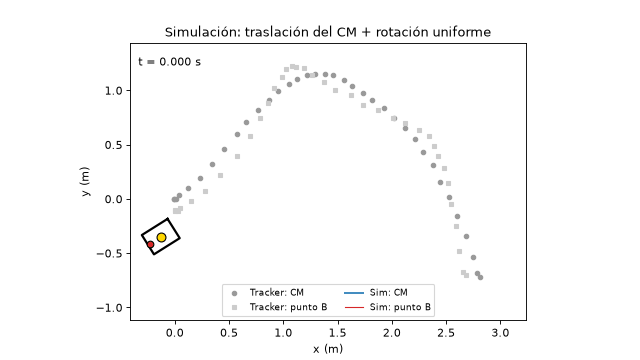

In [19]:

import os, tempfile

def simular(tiempos, x0, y0, v0, ang_grados, omega, theta0, g, r):
    # Ecuaciones de aceleración constante (CM) y rotación uniforme (θ).
    phi = np.radians(ang_grados)
    x = x0 + v0 * np.cos(phi) * tiempos
    y = y0 + v0 * np.sin(phi) * tiempos - 0.5 * g * tiempos**2
    th = theta0 + omega * tiempos
    return x, y, th, x + r * np.cos(th), y + r * np.sin(th)

def esquinas_caja(xc, yc, ang, a=A_L, b=B_L):
    # Vértices del rectángulo a×b centrado en (xc, yc) y girado un ángulo ang.
    loc = np.array([[-a, -b], [a, -b], [a, b], [-a, b], [-a, -b]]) / 2
    R = np.array([[np.cos(ang), -np.sin(ang)], [np.sin(ang), np.cos(ang)]])
    return loc @ R.T + [xc, yc]

def animar(x0=X0_SIM, y0=Y0_SIM, v0=V0_SIM, ang=ANG_SIM, omega=OMEGA_SIM,
           theta0=THETA0_SIM, g=G_SIM, r=R_SIM, T=T_SIM, datos_exp=True, fps=30):
    ts = np.arange(0, T + 1e-9, 1 / fps)
    xs, ys, ths, xbs, ybs = simular(ts, x0, y0, v0, ang, omega, theta0, g, r)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    m = 0.15
    # Los límites incluyen el objeto completo y, si se muestran, los datos de Tracker
    xref = np.concatenate([xs, xA]) if datos_exp else xs
    yref = np.concatenate([ys, yA]) if datos_exp else ys
    m = max(m, A_L)
    ax.set(xlim=(xref.min() - m, xref.max() + m),
           ylim=(yref.min() - m, yref.max() + m),
           title="Simulación: traslación del CM + rotación uniforme", xlabel="x (m)", ylabel="y (m)")
    ax.set_aspect("equal")
    if datos_exp:
        ax.plot(xA, yA, "o", ms=4, color="0.6", label="Tracker: CM")
        ax.plot(xB, yB, "s", ms=3, color="0.8", label="Tracker: punto B")
    caja, = ax.plot([], [], "-", color="k", lw=2)
    trayA, = ax.plot([], [], "-", color="C0", lw=1.5, label="Sim: CM")
    trayB, = ax.plot([], [], "-", color="C3", lw=1, label="Sim: punto B")
    ptA, = ax.plot([], [], "o", color="gold", mec="k", ms=8)
    ptB, = ax.plot([], [], "o", color="C3", mec="k", ms=6)
    txt = ax.text(0.02, 0.95, "", transform=ax.transAxes, va="top")
    ax.legend(loc="lower center", fontsize=8, ncol=2)

    def cuadro(i):
        e = esquinas_caja(xs[i], ys[i], ths[i] + PHI_CAJA)
        caja.set_data(e[:, 0], e[:, 1])
        trayA.set_data(xs[:i + 1], ys[:i + 1]); trayB.set_data(xbs[:i + 1], ybs[:i + 1])
        ptA.set_data([xs[i]], [ys[i]]); ptB.set_data([xbs[i]], [ybs[i]])
        txt.set_text(f"t = {ts[i]:.3f} s")
        return caja, trayA, trayB, ptA, ptB, txt

    anim = animation.FuncAnimation(fig, cuadro, frames=len(ts), interval=1000 / fps, blit=True)
    # Se guarda como GIF: a diferencia de to_jshtml(), se ve aunque el notebook no sea "confiable"
    with tempfile.TemporaryDirectory() as carpeta:
        ruta = os.path.join(carpeta, "animacion.gif")
        anim.save(ruta, writer=animation.PillowWriter(fps=fps), dpi=80)
        with open(ruta, "rb") as archivo:
            gif = archivo.read()
    plt.close(fig)
    return Image(data=gif, format="gif")


def rmse(pred, real):
    return np.sqrt(np.mean((pred - real)**2))

# Mostrar la animación con las condiciones del experimento
display(animar())

In [20]:
# =====================================================================
#  SIMULADOR INTERACTIVO
#  Valores iniciales: los del experimento (celda de condiciones iniciales).
#  Requiere un kernel activo: ejecuten esta celda para usar los controles.
# =====================================================================
try:
    import ipywidgets as widgets
except ImportError:
    widgets = None
    print("Falta ipywidgets (pip install ipywidgets). "
          "Las condiciones iniciales también se pueden cambiar en la celda de variables.")

VALORES_EXPERIMENTO = dict(x0=X0_SIM, y0=Y0_SIM, v0=V0_SIM, ang=ANG_SIM, omega=OMEGA_SIM,
                           theta0=THETA0_SIM, g=G_SIM, T=T_SIM)

def dibujar_vista(x0, y0, v0, ang, omega, theta0, g, T, datos_exp=True, r=R_SIM):
    # Vista rápida: trayectorias y varias posiciones del objeto, sin animar.
    ts = np.arange(0, T + 1e-9, 1 / 60)
    xs, ys, ths, xbs, ybs = simular(ts, x0, y0, v0, ang, omega, theta0, g, r)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    if datos_exp:
        ax.plot(xA, yA, "o", ms=4, color="lightblue", label="Tracker: CM")
        ax.plot(xB, yB, "s", ms=3, color="hotpink", label="Tracker: punto B")
    ax.plot(xs, ys, "-", color="lightpink", lw=1.5, label="Simulación: CM")
    ax.plot(xbs, ybs, "-", color="purple", lw=1, label="Simulación: punto B")
    for i in np.linspace(0, len(ts) - 1, 6).astype(int):
        e = esquinas_caja(xs[i], ys[i], ths[i] + PHI_CAJA)
        ax.plot(e[:, 0], e[:, 1], "-", color="k", lw=1, alpha=0.45)
    ax.plot([], [], "-", color="k", lw=1, alpha=0.45, label="Funda (6 instantes)")
    ax.set(title="Vista previa de la simulación", xlabel="x (m)", ylabel="y (m)")
    ax.set_aspect("equal", adjustable="datalim"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    return fig

def resumen_vista(x0, y0, v0, ang, omega, theta0, g, T, datos_exp=True, r=R_SIM):
    # Resultados de la teoría y diferencia con Tracker para las condiciones elegidas.
    phi = np.radians(ang)
    vx, vy = v0 * np.cos(phi), v0 * np.sin(phi)
    y_max = y0 + vy**2 / (2 * g) if vy > 0 else y0     # máximo de la parábola
    alcance = 2 * vx * vy / g                          # hasta volver a la altura inicial
    xs, ys, ths, _, _ = simular(t, x0, y0, v0, ang, omega, theta0, g, r)
    return (f"<b>v0x</b> = {vx:.2f} m/s &nbsp; <b>v0y</b> = {vy:.2f} m/s &nbsp; "
            f"<b>y máx</b> = {y_max:.2f} m &nbsp; <b>alcance</b> = {alcance:.2f} m &nbsp; "
            f"<b>vueltas</b> = {abs(omega) * T / (2 * np.pi):.2f}<br>"
            f"<b>Diferencia con Tracker (RMSE):</b> x = {1000 * rmse(xs, xA):.0f} mm, "
            f"y = {1000 * rmse(ys, yA):.0f} mm, θ = {rmse(ths, theta):.2f} rad")

if widgets is not None:
    def deslizador(texto, clave, minimo, maximo, paso):
        return widgets.FloatSlider(value=VALORES_EXPERIMENTO[clave], min=minimo, max=maximo, step=paso,
                                   description=texto, readout_format=".2f", continuous_update=False,
                                   style={"description_width": "150px"}, layout=widgets.Layout(width="440px"))

    controles = {
        "x0":     deslizador("x₀ (m)", "x0", -2.0, 2.0, 0.01),
        "y0":     deslizador("y₀ (m)", "y0", -2.0, 3.0, 0.01),
        "v0":     deslizador("Rapidez v₀ (m/s)", "v0", 0.0, 15.0, 0.01),
        "ang":    deslizador("Ángulo de lanzamiento (°)", "ang", 0.0, 180.0, 0.1),
        "omega":  deslizador("ω (rad/s)", "omega", -30.0, 30.0, 0.01),
        "theta0": deslizador("θ₀ (rad)", "theta0", -2 * np.pi, 2 * np.pi, 0.01),
        "g":      widgets.Dropdown(options=[(f"Ajustada ({g_fit:.2f} m/s²)", g_fit),
                                            (f"Aceptada ({G_ACEPTADA:.2f} m/s²)", G_ACEPTADA)],
                                   value=G_SIM, description="g",
                                   style={"description_width": "150px"}, layout=widgets.Layout(width="440px")),
        "T":      deslizador("Duración (s)", "T", 0.2, 4.0, 0.01),
    }
    ver_datos = widgets.Checkbox(value=True, description="Superponer datos de Tracker")
    boton_animar = widgets.Button(description="▶ Animar", button_style="success")
    boton_restaurar = widgets.Button(description="↺ Experimento")
    salida_texto = widgets.HTML()
    salida_vista = widgets.Output()
    salida_anim = widgets.Output()

    def valores_actuales():
        return {clave: control.value for clave, control in controles.items()}

    restaurando = False

    def actualizar(_=None):
        # Redibuja la vista previa y borra la animación anterior, que ya no corresponde.
        if restaurando:
            return
        valores = valores_actuales()
        salida_texto.value = resumen_vista(**valores)
        salida_anim.clear_output()
        with salida_vista:
            salida_vista.clear_output(wait=True)
            fig = dibujar_vista(**valores, datos_exp=ver_datos.value)
            display(fig)
            plt.close(fig)

    def al_animar(_):
        # Genera la animación con las condiciones actuales (tarda unos segundos).
        boton_animar.disabled = True
        boton_animar.description = "Generando…"
        try:
            with salida_anim:
                salida_anim.clear_output(wait=True)
                display(animar(**valores_actuales(), datos_exp=ver_datos.value))
        finally:
            boton_animar.disabled = False
            boton_animar.description = "▶ Animar"

    def al_restaurar(_):
        # Vuelve a las condiciones iniciales del experimento.
        global restaurando
        restaurando = True
        for clave, control in controles.items():
            control.value = VALORES_EXPERIMENTO[clave]
        restaurando = False
        actualizar()

    for control in list(controles.values()) + [ver_datos]:
        control.observe(actualizar, names="value")
    boton_animar.on_click(al_animar)
    boton_restaurar.on_click(al_restaurar)

    display(widgets.VBox([widgets.HBox([widgets.VBox(list(controles.values())),
                                        widgets.VBox([ver_datos, boton_animar, boton_restaurar])]),
                          salida_texto, salida_vista, salida_anim]))
    actualizar()


## comparacion con los datos del tracker

Con las condiciones iniciales del experimento, la predicción se evalúa en los mismos instantes de Tracker y se mide la diferencia con el error cuadrático medio (RMSE) en $x$, $y$ y $\theta$.

,RMSE x (mm),RMSE y (mm),RMSE θ (rad)
"Simulación, todas las filas",52.234,104.790,0.314
"Simulación, solo filas de vuelo libre",27.208,69.724,0.209
Parámetros reajustados al vuelo libre,23.001,28.973,0.109


En t = 0: y simulada = -0.347 m, y medida = 0.000 m; θ simulado = -2.580 rad, θ medido = -1.373 rad


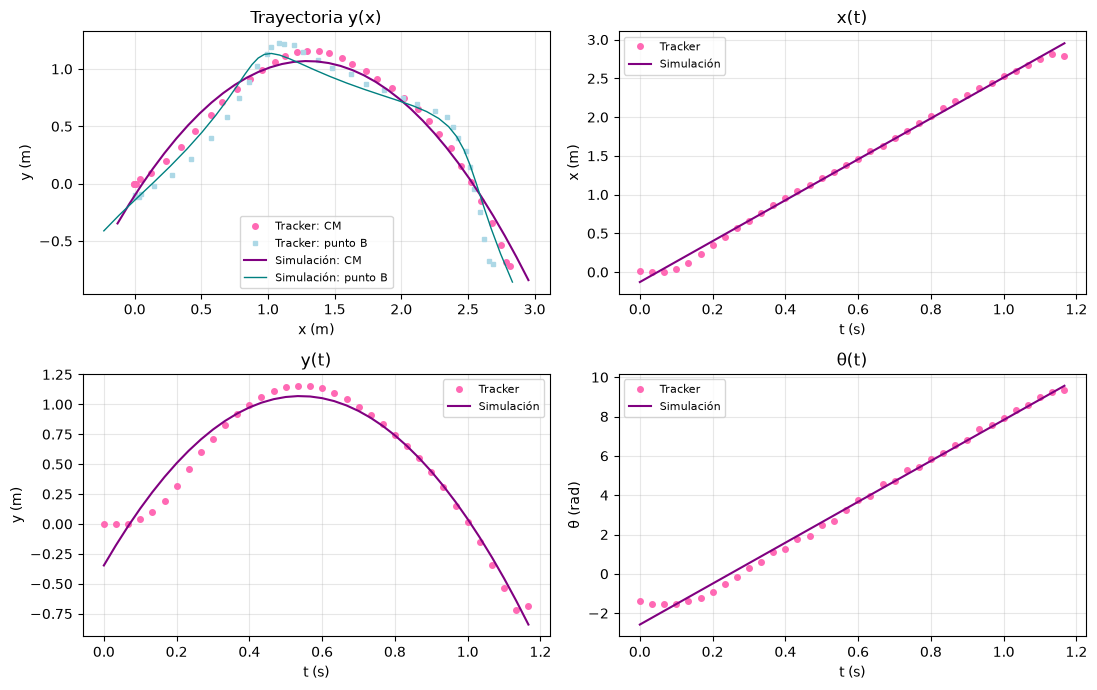

In [21]:
# =====================================================================
#  COMPARACIÓN: predicción con las condiciones del experimento vs. Tracker
# =====================================================================
def rmse(a, b):
    # Error cuadrático medio entre dos series evaluadas en los mismos instantes.
    return np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2))

# Predicción en los mismos instantes de Tracker (t, xA, yA y theta salen de 2.2 y 2.3)
x_sim, y_sim, th_sim, xb_sim, yb_sim = simular(t, X0_SIM, Y0_SIM, V0_SIM, ANG_SIM,
                                               OMEGA_SIM, THETA0_SIM, G_SIM, R_SIM)

# Reajuste con solo las filas de vuelo libre, para medir cuánto error aportan las demás
tv = t[en_vuelo] - t[en_vuelo][0]
cxv, _, _ = ajuste(tv, xA[en_vuelo], 1)
cyv, _, _ = ajuste(tv, yA[en_vuelo], 2)
ctv, _, _ = ajuste(tv, theta[en_vuelo], 1)

tabla_rmse = pd.DataFrame(
    [[1000 * rmse(x_sim, xA), 1000 * rmse(y_sim, yA), rmse(th_sim, theta)],
     [1000 * rmse(x_sim[en_vuelo], xA[en_vuelo]), 1000 * rmse(y_sim[en_vuelo], yA[en_vuelo]),
      rmse(th_sim[en_vuelo], theta[en_vuelo])],
     [1000 * rmse(np.polyval(cxv, tv), xA[en_vuelo]), 1000 * rmse(np.polyval(cyv, tv), yA[en_vuelo]),
      rmse(np.polyval(ctv, tv), theta[en_vuelo])]],
    columns=["RMSE x (mm)", "RMSE y (mm)", "RMSE θ (rad)"],
    index=["Simulación, todas las filas",
           "Simulación, solo filas de vuelo libre",
           "Parámetros reajustados al vuelo libre"])
display(tabla_rmse.round(3))
print(f"En t = 0: y simulada = {y_sim[0]:.3f} m, y medida = {yA[0]:.3f} m; "
      f"θ simulado = {th_sim[0]:.3f} rad, θ medido = {theta[0]:.3f} rad")

fig, axs = plt.subplots(2, 2, figsize=(11, 7))
axs[0, 0].plot(xA, yA, "o", ms=4, color="hotpink", label="Tracker: CM")
axs[0, 0].plot(xB, yB, "s", ms=3, color="lightblue", label="Tracker: punto B")
axs[0, 0].plot(x_sim, y_sim, "-", color="purple", label="Simulación: CM")
axs[0, 0].plot(xb_sim, yb_sim, "-", lw=1, color="teal", label="Simulación: punto B")
axs[0, 0].set(title="Trayectoria y(x)", xlabel="x (m)", ylabel="y (m)")
for ax, med, sim, nom, uni in [(axs[0, 1], xA, x_sim, "x", "m"), (axs[1, 0], yA, y_sim, "y", "m"),
                               (axs[1, 1], theta, th_sim, "θ", "rad")]:
    ax.plot(t, med, "o", ms=4, color="hotpink", label="Tracker")
    ax.plot(t, sim, "-", color="purple", label="Simulación")
    ax.set(title=f"{nom}(t)", xlabel="t (s)", ylabel=f"{nom} ({uni})")
for ax in axs.flat:
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


# Respuesta sección 2.6


**1. ¿La trayectoria del centro de masa coincide con la de una partícula bajo gravedad?**
En forma, sí: $x(t)$ es aproximadamente lineal y $y(t)$ parabólica. El ajuste de las 36 filas da $g = 9{,}71 \pm 0{,}35$ m/s², un error de 0,97 %. El acuerdo cuantitativo es menos sólido: en vuelo libre se obtiene $g = 11{,}64 \pm 0{,}18$ m/s² (2.5), probablemente por un error de escala, y además hay un arrastre de ~0,1 N (2.4).

**2. ¿La velocidad angular respecto al centro de masa permanece constante? ¿Por qué?**
Aproximadamente. El ajuste da $\omega = 10{,}41 \pm 0{,}17$ rad/s y en vuelo libre $\omega = 11{,}04 \pm 0{,}08$ rad/s. La prueba cuadrática no sale exactamente nula: $\alpha = 2{,}5 \pm 0{,}9$ rad/s² con todas las filas, por los primeros cuadros, en los que casi no gira, y $\alpha = -1{,}6 \pm 0{,}6$ rad/s² en vuelo libre, lo que equivale a un cambio de ~1,4 rad/s (13 %) durante el vuelo. El peso no produce torque respecto al CM, así que $L_{cm} = I_{cm}\omega$ se conservaría sin aire; la pequeña variación puede venir del torque del aire y del ruido de marcado.

**3. ¿Qué relación hay entre la velocidad lineal de un punto del objeto y su velocidad angular?**
Respecto al CM, el punto describe una circunferencia de radio $r$ con $v_{rel} = \omega r$. Las medidas son compatibles: $1{,}17 \pm 0{,}36$ m/s frente a $\omega r = 1{,}26 \pm 0{,}13$ m/s. Respecto al suelo, $\vec v_B = \vec v_{cm} + \vec\omega\times\vec r_{B/A}$.

**4. ¿Qué concluyen sobre la independencia entre traslación y rotación?**
El movimiento se puede tratar como una traslación del CM, gobernada por $\sum\vec F = m\vec a_{cm}$, más una rotación alrededor del CM, gobernada por $\sum\tau_{cm} = I_{cm}\alpha$. Con el peso como fuerza dominante, $\vec a_{cm}$ no depende del giro y el peso no cambia $\omega$. La simulación trata ambas partes por separado y reproduce la forma del movimiento, con las discrepancias explicadas en la sección 5.

**5. ¿Se conserva la energía mecánica total?**
No exactamente. Con todas las filas varía 3,05 J porque la mano entrega energía al inicio y la última fila es posterior al impacto. En vuelo libre, la media es 1,92 J, con desviación estándar de 0,16 J y una tendencia de $-0{,}44 \pm 0{,}08$ J/s. Las gráficas de 2.4 muestran mucha dispersión por el ruido de derivar y una pérdida neta de ~0,4 J, del orden del trabajo del arrastre.

##  Conclusiones
- La funda en vuelo es un ejemplo de **movimiento compuesto**: su CM describe aproximadamente una parábola (cinemática) mientras gira alrededor de él con $\omega$ casi constante (dinámica del cuerpo rígido), porque el peso no ejerce torque respecto al CM.
- El DCL (estática) muestra que el peso y la resistencia del aire no se equilibran, de modo que el CM acelera.
- Con las 36 filas se obtuvo $g = 9{,}71 \pm 0{,}35$ m/s² (error de 0,97 %) y $\omega = 10{,}41 \pm 0{,}17$ rad/s. El resultado de $g$ depende mucho de las filas elegidas: en vuelo libre es $11{,}64 \pm 0{,}18$ m/s², lo que apunta a un error de escala. La referencia debe estar en el plano del movimiento.
- En vuelo libre, el momento horizontal y la energía mecánica disminuyen (−0,11 N y ~0,4 J), de forma compatible con un arrastre de ~0,1 N (cinética). La hipótesis de conservación es una aproximación.
- La simulación usa los parámetros ajustados y reproduce la forma del movimiento, con RMSE de 52 mm en $x$ y 105 mm en $y$. La mayor parte del error viene de ajustar también filas que no son de vuelo libre.

#  Contribución de cada integrante
- **Maria Alejandra Diaz:** Se encargó del análisis del video mediante el software Tracker, la organización y estructuración del notebook, así como de la redacción de algunos apartados del informe. También participó en la elaboración y organización de las tablas y gráficas correspondientes a los resultados experimentales.
- **Daniel Alvarado Galvis:**  Participó en la redacción de algunos apartados del informe, realizó los cálculos necesarios para el desarrollo del proyecto, elaboró el diagrama de cuerpo libre (DCL) y llevó a cabo la investigación y consulta de las fuentes bibliográficas utilizadas.
- **Santiago Aguilar Vesga:** Estuvo a cargo de la programación del simulador, la implementación de los cálculos físicos en código y la corrección de errores ortográficos del documento, contribuyendo a la revisión y presentación final del trabajo.

# Fuentes consultadas
1. Serway, R. A., & Jewett, J. W. (2019). *Física para ciencias e ingeniería* (10.ª ed., Vol. 1). Cengage. Cap. 4 (movimiento en dos dimensiones), cap. 10–11 (rotación, tabla 10.2 de momentos de inercia).
2. Beer, F. P., Johnston, E. R., & Cornwell, P. J. (2017). *Mecánica vectorial para ingenieros: Dinámica* (11.ª ed.). McGraw-Hill. Cap. 15–16 (cinemática y movimiento plano de cuerpos rígidos).
3. Brown, D. (2024). *Tracker Video Analysis and Modeling Tool* (v6.3). Open Source Physics. https://physlets.org/tracker/
4. Harris, C. R., et al. (2020). Array programming with NumPy. *Nature*, 585, 357–362. · Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering*, 9(3), 90–95.
5. **Herramientas de apoyo:** se usó Claude (Anthropic), un asistente de inteligencia artificial, para revisar los datos de Tracker, estructurar el código del notebook y redactar borradores de los textos. Todo el contenido fue revisado por los integrantes.